# PPMI Modality Analysis: Harmonized Longitudinal Cohort Spine
**Notebook**: `eda_pca_curated.ipynb`  
**Modality Group**: `curated` (3 Scoped Analyzable Units)  
**Authoritative Scope**: `docs/important_modality_files.md`  
**Cohort Policy (Revision 4)**: Parkinson's disease (`PD`) and Healthy Controls (`HC`) Only  
**PCA Architecture**: Shared-space class-balanced component space fit on 1 deterministic record per participant  
**Governance Framework**: Codex Supervisory Review & `AGENTS.md` Task `EDA-PCA-001`  

---

## Modality Overview
Master curated longitudinal milestone cuts (PPMI_Curated_Data_Cut_Public_20260810) harmonizing clinical, biofluid, and demographic features across visits.

### Scientific & Governance Invariants
1. **Target Cohort Restriction**: Analytical populations and PCA models are restricted exclusively to verified **Parkinson's disease (`PD`)** and **Healthy Controls (`HC`)**. Excluded classes (SWEDD, prodromal, genetic non-motor carriers) are filtered out prior to analysis. Cohort labels and disease staging fields never enter the PCA feature matrix.
2. **Participant-Level Shared-Space PCA**: For eligible participant-level tables, repeated visits are resolved to 1 record per participant (baseline preferred with stable tie-breaking and completeness checks). PCA and preprocessing (median imputation, scaling) are fit exclusively on a shared, deterministically class-balanced sample ($k = \min(N_{PD}, N_{HC})$, sampled via SHA-256 hash ranking) to reduce direct sample-count influence on component orientation, and all target participants are projected into this identical space.
3. **Comprehensive Committed EDA (Correction C1 / R4-02)**: Exact schemas with variable roles, missingness, duplicate rows, observation grain, numeric skewness, Tukey IQR and z-score outlier metrics, and categorical frequency summaries are visibly rendered in this notebook and committed directly to disk.
4. **Privacy-Safe Displays (Correction C3 / R4-05)**: Scree plots, loadings tables, and 2x2 side-by-side PD vs HC hexbin density score plots with cell suppression ($< 5$ observations masked) and outlier disclosures.
5. **Committed State Reproducibility (Correction C4 / R4-04)**: Loads directly from committed reports (`EDA/outputs/reports/`) using repository-relative POSIX paths with zero dependence on ignored cache.

In [1]:
import os
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 10

# Resolve repository root
repo_root = Path.cwd().resolve()
if (repo_root / "EDA" / "src").exists():
    sys.path.insert(0, str(repo_root / "EDA" / "src"))
elif (repo_root.parent / "EDA" / "src").exists():
    repo_root = repo_root.parent
    sys.path.insert(0, str(repo_root / "EDA" / "src"))

from ppmi_pipeline.reporting.privacy import PrivacyGuard

print(f"Environment initialized. Modality: 'curated', Dynamic repository root: ppmi")

Environment initialized. Modality: 'curated', Dynamic repository root: ppmi


## 1. Scoped Analyzable Units in Harmonized Longitudinal Cohort Spine
The authoritative catalog assigns exactly **3 analyzable unit(s)** to this modality domain.

In [2]:
manifest_path = repo_root / "EDA" / "outputs" / "reports" / "priority_eda_pca_manifest.json"
with open(manifest_path, "r", encoding="utf-8") as f:
    manifest_data = json.load(f)

mod_units = [u for u in manifest_data["units"] if u.get("modality_group") == 'curated']

inv_rows = []
for unit_entry in mod_units:
    sheet_suffix = (" -> [" + str(unit_entry.get("sheet_name")) + "]") if unit_entry.get("sheet_name") else ""
    pca_stat_str = ("COMPLETED (" + str(unit_entry.get("pca_included_features_count", 0)) + " feats)") if unit_entry.get("pca_status") == "COMPLETED" else str(unit_entry.get("pca_skip_reason"))
    inv_rows.append({
        "Unit Slug": unit_entry["unit_slug"],
        "Filename / Sheet": str(unit_entry.get("declared_filename")) + sheet_suffix,
        "Physical Exists": "Yes" if unit_entry.get("physical_exists") else "No (Absent)",
        "EDA Status": unit_entry.get("eda_status"),
        "PCA Status": unit_entry.get("pca_status"),
        "PCA Reason / Features": pca_stat_str
    })

inv_df = pd.DataFrame(inv_rows)
display(inv_df)
print(f"Total units cataloged: {len(inv_df)} | EDA Completed: {(inv_df['EDA Status'] == 'COMPLETED').sum()} | PCA Completed: {(inv_df['PCA Status'] == 'COMPLETED').sum()}")

,Unit Slug,Filename / Sheet,Physical Exists,EDA Status,PCA Status,PCA Reason / Features
0,curated_datacuts_PPMI_Curated_Data_Cut_P__2026...,PPMI_Curated_Data_Cut_Public_20260810.csv -> [...,Yes,COMPLETED,COMPLETED,COMPLETED (59 feats)
1,curated_datacuts_PPMI_Curated_Data_Cut_P__Data...,PPMI_Curated_Data_Cut_Public_20260810(1).xlsx ...,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...
2,curated_datacuts_PPMI_Curated_Data_Cut_P__Info...,PPMI_Curated_Data_Cut_Public_20260810(1).xlsx ...,Yes,COMPLETED,SKIPPED,Insufficient usable numeric analytical feature...


Total units cataloged: 3 | EDA Completed: 3 | PCA Completed: 1


---
## 2.1. Unit: `PPMI_Curated_Data_Cut_Public_20260810.csv` [20260810]
- **Unit Slug**: `curated_datacuts_PPMI_Curated_Data_Cut_P__20260810`
- **Source Path**: `curated_datacuts/PPMI_Curated_Data_Cut_Public_20260810(1).xlsx`
- **Committed Unit Artifact**: [`curated_datacuts_PPMI_Curated_Data_Cut_P__20260810.json`](../EDA/outputs/reports/units/curated_datacuts_PPMI_Curated_Data_Cut_P__20260810.json)
- **Declared Observation Grain**: `(PATNO, EVENT_ID)`
- **Selection Tier**: `Primary EDA` | **Role**: `Master longitudinal matrix containing demographics, cohort status, diagnosis age, motor summaries, cognitive metrics, and core biofluid markers.`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `COMPLETED`

UNIT ANALYSIS: curated_datacuts/PPMI_Curated_Data_Cut_Public_20260810(1).xlsx -> [20260810]
EDA Status: COMPLETED | PCA Status: COMPLETED
Dimensions: 10,779 analyzed rows x 216 columns
Observation Grain: Participant-by-event repeated clinical observation (PATNO, EVENT_ID)
Candidate Primary Keys: [['PATNO', 'EVENT_ID']]

Target Cohort Filtering Denominators:
  - Initial Rows: 20,408 (5,019 participants)
  - PD Retained:  8,546 rows (1,684 participants)
  - HC Retained:  2,233 rows (336 participants)
  - Non-Target Excluded: 9,629 rows (SWEDD/Prodromal)
  - Unmatched Excluded:  0 rows

Exact Variable Schema & Storage Types (216 columns):
Showing first 20 of 216 columns (complete schema committed to curated_datacuts_PPMI_Curated_Data_Cut_P__20260810.json):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,SITE,int64,0,0.0%,55,Analytical Numeric Measurement
1,PATNO,int64,0,0.0%,"2,020",Identifier
2,COHORT,int64,0,0.0%,2,Cohort / Stratification Label
3,subgroup,object,0,0.0%,16,Cohort / Stratification Label
4,enroll_phase,int64,0,0.0%,2,Administrative / Staging Metadata
5,enroll_source,object,"10,779",100.0%,0,Administrative / Staging Metadata
6,analytic_subgroup,object,"10,779",100.0%,0,Cohort / Stratification Label
7,HIQ_RBD,float64,"10,779",100.0%,0,Analytical Numeric Measurement
8,study_status,object,0,0.0%,3,Administrative Metadata
9,Death_Status,float64,"1,495",13.9%,2,Administrative Metadata



Variable Role Distribution Summary:


,Count
variable_role,
Analytical Numeric Measurement,169
Demographic / Covariate,14
Administrative / Staging Metadata,10
Date / Timestamp / Visit,7
Identifier,4
Cohort / Stratification Label,4
Administrative Metadata,3
Diagnostic / Categorical Code,3
Categorical / Text,2



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 782,906 / 2,328,264 (33.63%)
  - Duplicate Rows Count: 0
  - Columns with Missing Values (202 total, top 8):


,name,missing_count,missing_percent,variable_role
5,enroll_source,"10,779",100.0%,Administrative / Staging Metadata
6,analytic_subgroup,"10,779",100.0%,Cohort / Stratification Label
7,HIQ_RBD,"10,779",100.0%,Analytical Numeric Measurement
17,OTHNEURO,"10,655",98.8%,Diagnostic / Categorical Code
14,NSD_Adjudicated,"10,629",98.6%,Analytical Numeric Measurement
167,bd_tau_plasma,"10,586",98.2%,Analytical Numeric Measurement
166,ptau217_plasma,"10,585",98.2%,Analytical Numeric Measurement
177,C2N_AB40,"10,507",97.5%,Analytical Numeric Measurement


... (4 outputs left out)

  * Feature: NSD_STAGE (Distinct Categories: 9)


,category,row_count
0,3,"3,805"
1,Not NSD,"3,046"
2,4,"1,887"
3,2b,743
4,5,233
5,2a,180
6,6,44
7,1a,24



Numeric Summaries & Outlier Diagnostics (196 continuous/discrete features):
Showing top 10 of 196 features (full distribution profiles in curated_datacuts_PPMI_Curated_Data_Cut_P__20260810.json):


,variable,mean,std,min,median,max,skewness,shape,iqr_outliers_count,zscore_outliers_count
0,SITE,37.674,19.321,10.000,31.000,79.000,0.639,Moderately skewed (positive),0,0
1,COHORT,1.207,0.405,1.000,1.000,2.000,1.445,Strongly skewed (positive),"2,233",0
2,enroll_phase,1.306,0.461,1.000,1.000,2.000,0.841,Moderately skewed (positive),0,0
3,Death_Status,0.143,0.350,0.000,0.000,1.000,2.044,Strongly skewed (positive),"1,324",0
4,age_death,77.275,8.619,40.773,78.296,95.690,-0.624,Moderately skewed (negative),25,6
5,NSD_Status,0.701,0.458,0.000,1.000,1.000,-0.878,Moderately skewed (negative),0,0
6,NSD_Adjudicated,1.000,0.000,1.000,1.000,1.000,0.000,Approximately symmetric,0,0
7,Clinical_Stage,2.887,1.046,1.000,3.000,6.000,-0.228,Approximately symmetric,0,0
8,PRIMDIAG,5.204,11.229,1.000,1.000,97.000,5.659,Strongly skewed (positive),"2,331",107
9,age,61.809,10.024,29.260,62.825,86.652,-0.502,Moderately skewed (negative),165,53


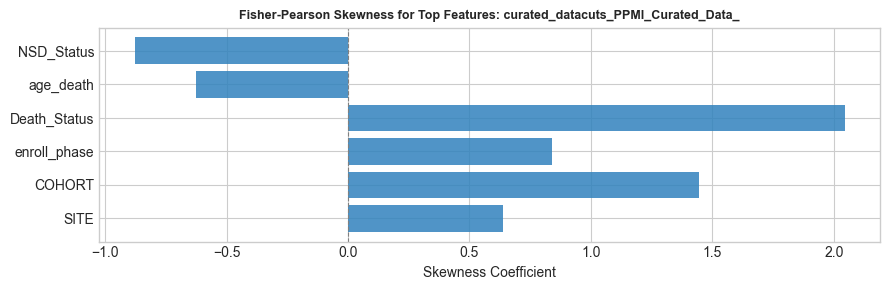

In [3]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "curated_datacuts_PPMI_Curated_Data_Cut_P__20260810.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: curated_datacuts/PPMI_Curated_Data_Cut_Public_20260810(1).xlsx -> [20260810]")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to curated_datacuts_PPMI_Curated_Data_Cut_P__20260810.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in curated_datacuts_PPMI_Curated_Data_Cut_P__20260810.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: curated_datacuts_PPMI_Curated_Data_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Shared-Space Class-Balanced Projection
- **Model Architecture**: One record per participant, fit strictly on balanced sample ($k = \min(N_{PD}, N_{HC})$)
- **Features Retained**: `59` continuous analytical measurements
- **Excluded Features**: `157` variables (identifiers, versions, demographics, codes, staging)
- **Explained Variance**: PC1 explains `13.4%` of shared multivariate variance

Shared-Space PCA Class Denominators:
  - Initial Eligible PD: 1,684 participants
  - Initial Eligible HC: 336 participants
  - Class-Balanced Fit Size: 336 participants per class (Total Fit N=672)
  - Total Projected Participants: 2,020


,Component,Individual Variance Ratio,Cumulative Variance Ratio
0,PC1,13.39%,13.39%
1,PC2,7.85%,21.25%
2,PC3,4.64%,25.89%
3,PC4,3.62%,29.51%
4,PC5,3.32%,32.82%



Top PC1 Feature Loadings:


,feature_name,loading
0,scopa_gi,0.2475
1,MSEADLG,-0.2354
2,gds,0.2159
3,LEDD,0.2122
4,NP1FATG,0.2108


Scree & Eigenvector Loadings Plot:


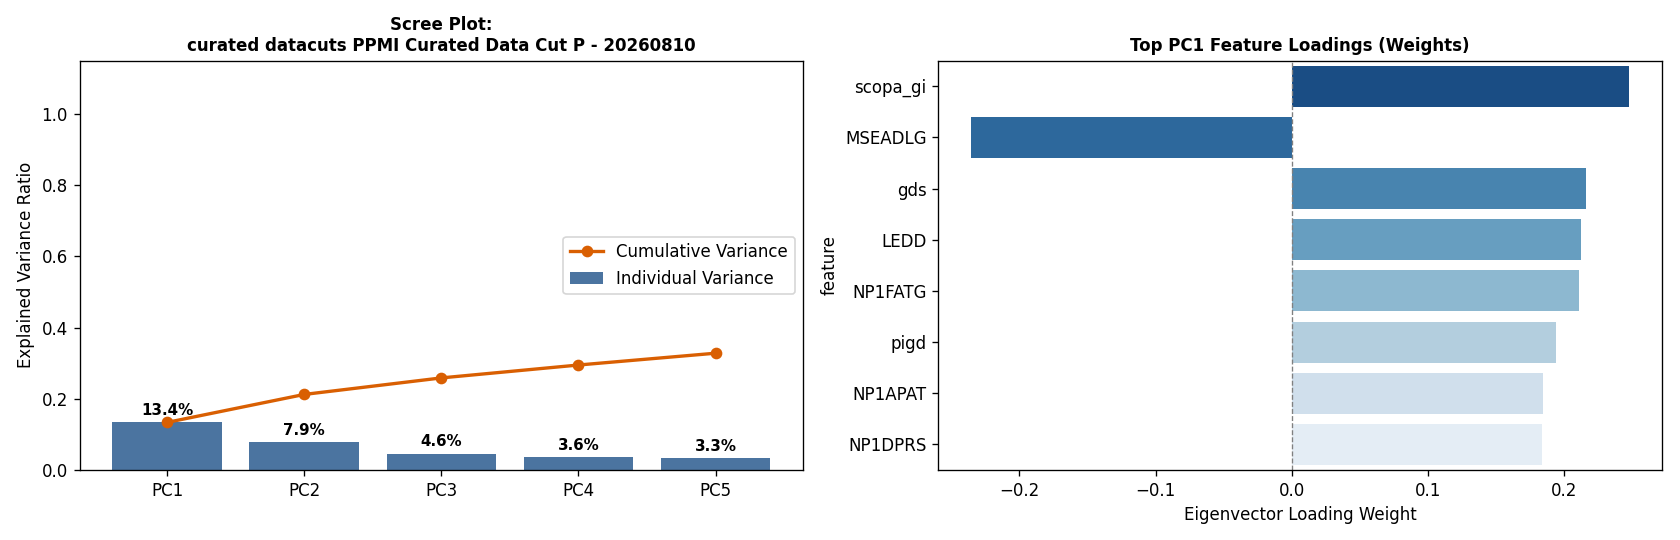

Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):


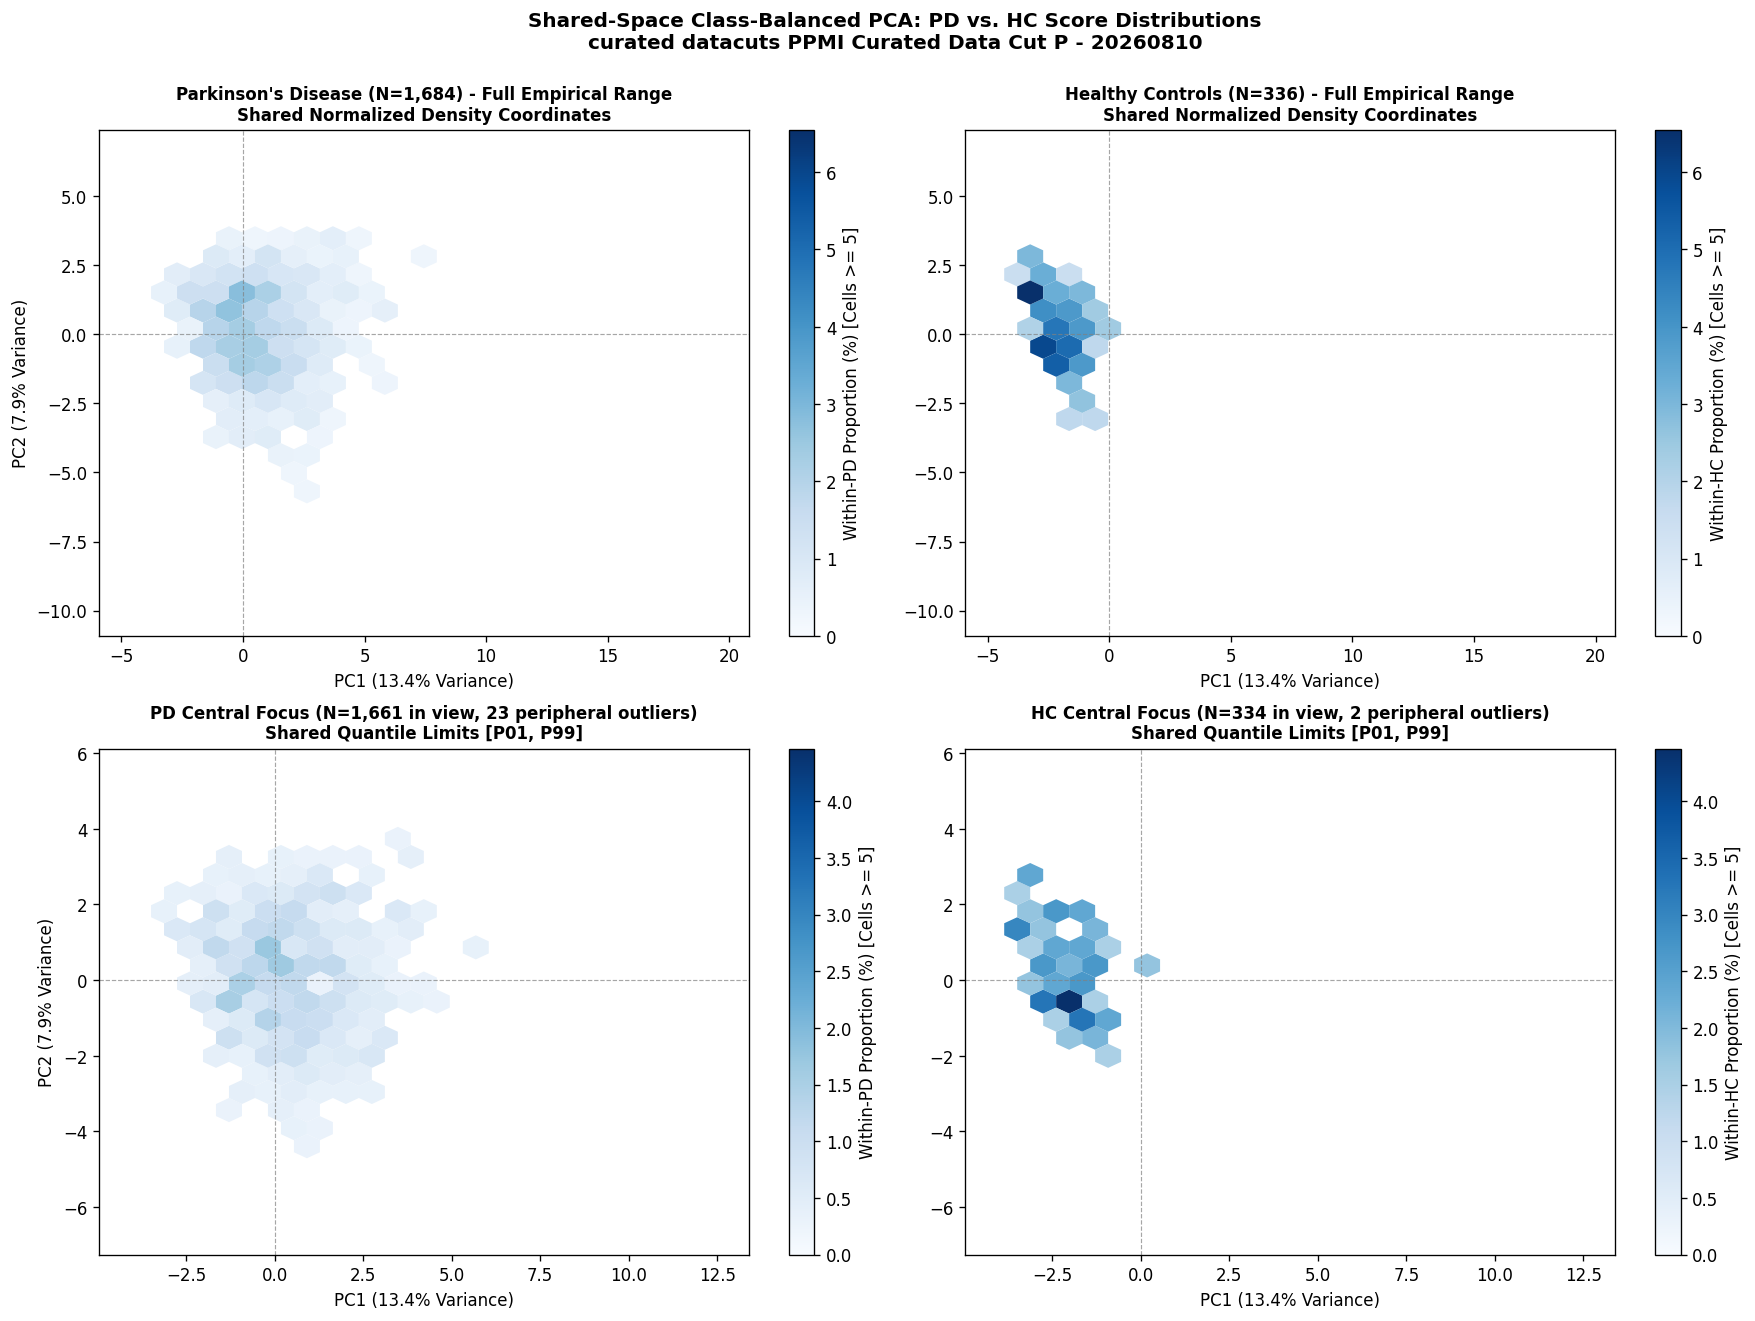

In [4]:
pca_res = unit_data["pca_results"]
c_denom = pca_res.get("class_denominators", {})

print("Shared-Space PCA Class Denominators:")
print(f"  - Initial Eligible PD: {c_denom.get('pd_initial_participants', 0):,} participants")
print(f"  - Initial Eligible HC: {c_denom.get('hc_initial_participants', 0):,} participants")
print(f"  - Class-Balanced Fit Size: {c_denom.get('balanced_fit_size_per_class', 0):,} participants per class (Total Fit N={c_denom.get('total_balanced_fit_observations', 0):,})")
print(f"  - Total Projected Participants: {c_denom.get('total_projected_participants', 0):,}")

# Explained Variance Table
exp_var = pca_res["explained_variance_ratio"]
cum_var = pca_res["cumulative_variance_ratio"]
var_df = pd.DataFrame({
    "Component": [f"PC{i+1}" for i in range(len(exp_var))],
    "Individual Variance Ratio": [f"{v:.2%}" for v in exp_var],
    "Cumulative Variance Ratio": [f"{v:.2%}" for v in cum_var]
})
display(var_df)

# Top PC1 and PC2 Loadings
top_pc1 = pd.DataFrame(pca_res.get("top_loadings_pc1", []))
top_pc2 = pd.DataFrame(pca_res.get("top_loadings_pc2", []))
print("\nTop PC1 Feature Loadings:")
display(top_pc1)

# Display Embedded Figures (Portable Relative Paths)
scree_rel = pca_res.get("scree_plot_path") or "EDA/outputs/reports/figures/scree_loadings/curated_datacuts_PPMI_Curated_Data_Cut_P__20260810_scree_loadings.png"
score_rel = pca_res.get("score_plot_path") or "EDA/outputs/reports/figures/pca_scores/curated_datacuts_PPMI_Curated_Data_Cut_P__20260810_pca_scores.png"
scree_path = repo_root / scree_rel if scree_rel else Path("NO_PATH")
score_path = repo_root / score_rel if score_rel else Path("NO_PATH")

if scree_path.exists():
    print("Scree & Eigenvector Loadings Plot:")
    display(Image(filename=str(scree_path)))

if score_path.exists():
    print("Privacy-Safe Shared-Space Side-by-Side Hexbin Score Density Plot (Cells < 5 Suppressed):")
    display(Image(filename=str(score_path)))

---
## 2.2. Unit: `PPMI_Curated_Data_Cut_Public_20260810(1).xlsx` [Data dictionary]
- **Unit Slug**: `curated_datacuts_PPMI_Curated_Data_Cut_P__Data_dictionary`
- **Source Path**: `curated_datacuts/PPMI_Curated_Data_Cut_Public_20260810(1).xlsx`
- **Committed Unit Artifact**: [`curated_datacuts_PPMI_Curated_Data_Cut_P__Data_dictionary.json`](../EDA/outputs/reports/units/curated_datacuts_PPMI_Curated_Data_Cut_P__Data_dictionary.json)
- **Declared Observation Grain**: `Sheet-dependent`
- **Selection Tier**: `Supporting` | **Role**: `Multi-tab workbook containing the primary curated cut (`[20260810]`), variable definitions (`[Data dictionary]`), and release changelogs (`[Information]`).`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

UNIT ANALYSIS: curated_datacuts/PPMI_Curated_Data_Cut_Public_20260810(1).xlsx -> [Data dictionary]
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 452 analyzed rows x 9 columns
Observation Grain: Non-participant table / documentation catalog
Candidate Primary Keys: []

Exact Variable Schema & Storage Types (9 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,Category,object,237,52.4%,8,Categorical / Text
1,Variable,object,237,52.4%,215,Categorical / Text
2,Description,object,237,52.4%,215,Categorical / Text
3,Code,object,2,0.4%,60,Categorical / Text
4,Decode,object,1,0.2%,146,Categorical / Text
5,Derived Variable,object,237,52.4%,2,Categorical / Text
6,Original Variable(s),object,238,52.6%,145,Categorical / Text
7,Original Dataset(s),object,243,53.8%,71,Categorical / Text
8,Derivation Notes,object,287,63.5%,145,Categorical / Text



Variable Role Distribution Summary:


,Count
variable_role,
Categorical / Text,9



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 1,719 / 4,068 (42.26%)
  - Duplicate Rows Count: 120
  - Columns with Missing Values (9 total, top 8):


,name,missing_count,missing_percent,variable_role
8,Derivation Notes,287,63.5%,Categorical / Text
7,Original Dataset(s),243,53.8%,Categorical / Text
6,Original Variable(s),238,52.6%,Categorical / Text
0,Category,237,52.4%,Categorical / Text
1,Variable,237,52.4%,Categorical / Text
2,Description,237,52.4%,Categorical / Text
5,Derived Variable,237,52.4%,Categorical / Text
3,Code,2,0.4%,Categorical / Text



Categorical Variable Frequency Distributions (2 variables profiled):
  * Feature: Category (Distinct Categories: 8)


,category,row_count
0,Clinical,114
1,Biologics,41
2,Demographics,17
3,'ID',12
4,NSD-ISS,10
5,DATSCAN,10
6,Milestones,7
7,Genetics,<5 (Suppressed)


  * Feature: Derived Variable (Distinct Categories: 2)


,category,row_count
0,Yes,169
1,No,46


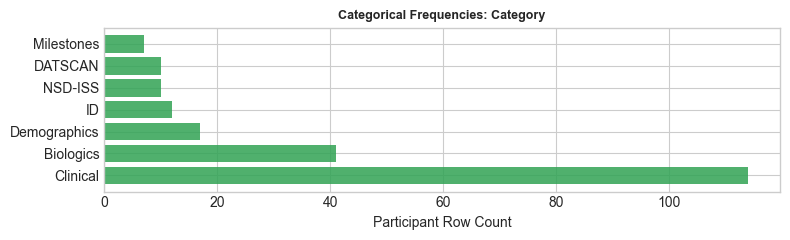

In [5]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "curated_datacuts_PPMI_Curated_Data_Cut_P__Data_dictionary.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: curated_datacuts/PPMI_Curated_Data_Cut_Public_20260810(1).xlsx -> [Data dictionary]")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to curated_datacuts_PPMI_Curated_Data_Cut_P__Data_dictionary.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in curated_datacuts_PPMI_Curated_Data_Cut_P__Data_dictionary.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: curated_datacuts_PPMI_Curated_Data_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [6]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 9 excluded

Excluded Variables Sample:


,feature_name,reason
0,Category,Non-numeric / categorical string or free text
1,Variable,Non-numeric / categorical string or free text
2,Description,"Identifier, date, visit, demographic, instrume..."
3,Code,Excessive missingness (47.6% > 40%)
4,Decode,Non-numeric / categorical string or free text
5,Derived Variable,Non-numeric / categorical string or free text
6,Original Variable(s),Non-numeric / categorical string or free text
7,Original Dataset(s),Non-numeric / categorical string or free text
8,Derivation Notes,"Identifier, date, visit, demographic, instrume..."


---
## 2.3. Unit: `PPMI_Curated_Data_Cut_Public_20260810(1).xlsx` [Information]
- **Unit Slug**: `curated_datacuts_PPMI_Curated_Data_Cut_P__Information`
- **Source Path**: `curated_datacuts/PPMI_Curated_Data_Cut_Public_20260810(1).xlsx`
- **Committed Unit Artifact**: [`curated_datacuts_PPMI_Curated_Data_Cut_P__Information.json`](../EDA/outputs/reports/units/curated_datacuts_PPMI_Curated_Data_Cut_P__Information.json)
- **Declared Observation Grain**: `Sheet-dependent`
- **Selection Tier**: `Supporting` | **Role**: `Multi-tab workbook containing the primary curated cut (`[20260810]`), variable definitions (`[Data dictionary]`), and release changelogs (`[Information]`).`
- **Terminal Statuses**: EDA: `COMPLETED` | PCA: `SKIPPED`

In [7]:
# Load committed unit artifact
unit_json_path = repo_root / "EDA" / "outputs" / "reports" / "units" / "curated_datacuts_PPMI_Curated_Data_Cut_P__Information.json"
with open(unit_json_path, "r", encoding="utf-8") as f:
    unit_data = json.load(f)

print("=" * 80)
print(f"UNIT ANALYSIS: curated_datacuts/PPMI_Curated_Data_Cut_Public_20260810(1).xlsx -> [Information]")
print("=" * 80)
print(f"EDA Status: {unit_data['eda_status']} | PCA Status: {unit_data['pca_status']}")

if unit_data.get("eda_status") == "UNREADABLE":
    print(f"UNREADABLE EVIDENCE: {unit_data.get('eda_unreadable_evidence')}")
else:
    eda = unit_data["eda_diagnostics"]
    print(f"Dimensions: {eda['row_count']:,} analyzed rows x {eda['column_count']} columns")
    print(f"Observation Grain: {eda['observation_grain']}")
    print(f"Candidate Primary Keys: {eda.get('candidate_primary_keys', [])}")

    # Cohort Denominator Evidence
    cohort_ev = eda.get("cohort_filter_evidence")
    if cohort_ev and cohort_ev.get("has_participant_data"):
        print("\nTarget Cohort Filtering Denominators:")
        print(f"  - Initial Rows: {cohort_ev.get('total_rows_pre_filter', 0):,} ({cohort_ev.get('distinct_participants_pre_filter', 0):,} participants)")
        print(f"  - PD Retained:  {cohort_ev.get('pd_rows_retained', 0):,} rows ({cohort_ev.get('pd_participants_retained', 0):,} participants)")
        print(f"  - HC Retained:  {cohort_ev.get('hc_rows_retained', 0):,} rows ({cohort_ev.get('hc_participants_retained', 0):,} participants)")
        print(f"  - Non-Target Excluded: {cohort_ev.get('nontarget_rows_excluded', 0):,} rows (SWEDD/Prodromal)")
        print(f"  - Unmatched Excluded:  {cohort_ev.get('unmatched_rows_excluded', 0):,} rows")

    # 1. Exact Column Schema & Types Table
    cols_df = pd.DataFrame(eda["column_profiles"])
    role_col = "variable_role" if "variable_role" in cols_df.columns else "role"
    schema_cols = [c for c in ["name", "dtype", "missing_count", "missing_percent", "distinct_count", role_col] if c in cols_df.columns]
    schema_view = cols_df[schema_cols].copy()
    if "missing_count" in schema_view.columns:
        schema_view["missing_count"] = schema_view["missing_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "distinct_count" in schema_view.columns:
        schema_view["distinct_count"] = schema_view["distinct_count"].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
    if "missing_percent" in schema_view.columns:
        schema_view["missing_percent"] = schema_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v) if pd.notna(v) else "-")

    print(f"\nExact Variable Schema & Storage Types ({len(cols_df)} columns):")
    if len(schema_view) <= 25:
        display(schema_view)
    else:
        print(f"Showing first 20 of {len(schema_view)} columns (complete schema committed to curated_datacuts_PPMI_Curated_Data_Cut_P__Information.json):")
        display(schema_view.head(20))

    print("\nVariable Role Distribution Summary:")
    display(cols_df[role_col].value_counts().to_frame("Count"))

    # 2. Missingness and Duplicate Quality Evidence
    print(f"\nMissingness & Duplicate Quality Evidence:")
    print(f"  - Total Missing Cells: {eda['total_missing_cells']:,} / {eda['row_count']*eda['column_count']:,} ({eda['overall_missing_percent']:.2f}%)")
    print(f"  - Duplicate Rows Count: {eda['duplicate_rows_count']}")
    high_missing = cols_df[cols_df["missing_percent"] > 0].sort_values("missing_percent", ascending=False)
    if not high_missing.empty:
        print(f"  - Columns with Missing Values ({len(high_missing)} total, top 8):")
        missing_view = high_missing[["name", "missing_count", "missing_percent", role_col]].head(8).copy()
        missing_view["missing_count"] = missing_view["missing_count"].apply(lambda v: "{:,}".format(int(v)))
        missing_view["missing_percent"] = missing_view["missing_percent"].apply(lambda v: "{:.1f}%".format(v))
        display(missing_view)
    else:
        print("  - Zero missing values detected across all columns.")

    # 3. Categorical Variable Frequency Summaries (<5 Suppressed)
    cat_summaries = eda.get("categorical_summaries", [])
    if cat_summaries:
        print(f"\nCategorical Variable Frequency Distributions ({len(cat_summaries)} variables profiled):")
        for cat_item in cat_summaries[:3]:
            var_name = cat_item.get("variable")
            freq_df = pd.DataFrame(cat_item.get("frequencies", []))
            print(f"  * Feature: {var_name} (Distinct Categories: {cat_item.get('distinct_count')})")
            if not freq_df.empty:
                freq_view = freq_df.copy()
                if "category" in freq_view.columns:
                    freq_view["category"] = freq_view["category"].apply(lambda c: "'" + str(c) + "'" if str(c).strip().upper() in ["ID", "PATNO", "SUBJID", "SUBJECT", "PARTICIPANT", "RECORD", "SAMPLE", "CASE", "PID", "RID"] else str(c))
                if "row_count" in freq_view.columns:
                    freq_view["row_count"] = freq_view["row_count"].apply(lambda v: "{:,}".format(int(v)) if isinstance(v, (int, float)) and pd.notna(v) else str(v))
                display(freq_view)
    else:
        print("\nCategorical Frequency Summaries: No multi-level categorical features for this unit.")

    # 4. Outlier and Numeric Summaries (Fisher-Pearson Skewness & Tukey IQR / Z-Score Diagnostics)
    if eda.get("numeric_summaries"):
        num_df = pd.DataFrame(eda["numeric_summaries"])
        print(f"\nNumeric Summaries & Outlier Diagnostics ({len(num_df)} continuous/discrete features):")
        var_col = "variable" if "variable" in num_df.columns else "name"
        cols_to_show = [c for c in [var_col, "mean", "std", "min", "median", "max", "skewness", "shape", "iqr_outliers_count", "zscore_outliers_count"] if c in num_df.columns]
        num_view = num_df[cols_to_show].copy()
        for count_col in ["iqr_outliers_count", "zscore_outliers_count"]:
            if count_col in num_view.columns:
                num_view[count_col] = num_view[count_col].apply(lambda v: "{:,}".format(int(v)) if pd.notna(v) else "-")
        if len(num_view) <= 12:
            display(num_view)
        else:
            print(f"Showing top 10 of {len(num_view)} features (full distribution profiles in curated_datacuts_PPMI_Curated_Data_Cut_P__Information.json):")
            display(num_view.head(10))

    # 5. Exploratory Data Visualization
    if eda.get("numeric_summaries") and len(eda["numeric_summaries"]) >= 2:
        top_num = pd.DataFrame(eda["numeric_summaries"]).head(6)
        var_col = "variable" if "variable" in top_num.columns else "name"
        fig, ax = plt.subplots(figsize=(9, 3.0))
        ax.barh(top_num[var_col], top_num["skewness"], color="#3182bd", alpha=0.85)
        ax.axvline(0, color="gray", linestyle="--", linewidth=0.8)
        ax.set_title(f"Fisher-Pearson Skewness for Top Features: curated_datacuts_PPMI_Curated_Data_", fontsize=9, fontweight="bold")
        ax.set_xlabel("Skewness Coefficient")
        plt.tight_layout()
        plt.show()
    elif cat_summaries and cat_summaries[0].get("frequencies"):
        first_cat = cat_summaries[0]
        cat_freq_df = pd.DataFrame(first_cat["frequencies"])
        valid_freqs = cat_freq_df[cat_freq_df["row_count"] != "<5 (Suppressed)"].copy()
        if not valid_freqs.empty and len(valid_freqs) >= 2:
            fig, ax = plt.subplots(figsize=(8, 2.5))
            ax.barh(valid_freqs["category"].astype(str), pd.to_numeric(valid_freqs["row_count"]), color="#31a354", alpha=0.85)
            ax.set_title(f"Categorical Frequencies: {first_cat['variable']}", fontsize=9, fontweight="bold")
            ax.set_xlabel("Participant Row Count")
            plt.tight_layout()
            plt.show()

UNIT ANALYSIS: curated_datacuts/PPMI_Curated_Data_Cut_Public_20260810(1).xlsx -> [Information]
EDA Status: COMPLETED | PCA Status: SKIPPED
Dimensions: 23 analyzed rows x 9 columns
Observation Grain: Non-participant table / documentation catalog
Candidate Primary Keys: []

Exact Variable Schema & Storage Types (9 columns):


,name,dtype,missing_count,missing_percent,distinct_count,variable_role
0,Revision Notes,object,4,17.4%,19,Categorical / Text
1,Date of Changes,object,7,30.4%,16,Date / Timestamp / Visit
2,Unnamed: 2,object,20,87.0%,3,Categorical / Text
3,Unnamed: 3,object,20,87.0%,3,Categorical / Text
4,Unnamed: 4,object,20,87.0%,3,Categorical / Text
5,Unnamed: 5,object,20,87.0%,3,Categorical / Text
6,Unnamed: 6,object,20,87.0%,3,Categorical / Text
7,Unnamed: 7,object,20,87.0%,3,Categorical / Text
8,Unnamed: 8,object,20,87.0%,3,Categorical / Text



Variable Role Distribution Summary:


,Count
variable_role,
Categorical / Text,8
Date / Timestamp / Visit,1



Missingness & Duplicate Quality Evidence:
  - Total Missing Cells: 151 / 207 (72.95%)
  - Duplicate Rows Count: 3
  - Columns with Missing Values (9 total, top 8):


,name,missing_count,missing_percent,variable_role
2,Unnamed: 2,20,87.0%,Categorical / Text
7,Unnamed: 7,20,87.0%,Categorical / Text
3,Unnamed: 3,20,87.0%,Categorical / Text
4,Unnamed: 4,20,87.0%,Categorical / Text
5,Unnamed: 5,20,87.0%,Categorical / Text
8,Unnamed: 8,20,87.0%,Categorical / Text
6,Unnamed: 6,20,87.0%,Categorical / Text
1,Date of Changes,7,30.4%,Date / Timestamp / Visit


... (2 outputs left out)

  * Feature: Unnamed: 3 (Distinct Categories: 3)


,category,row_count
0,Column C,<5 (Suppressed)
1,Description,<5 (Suppressed)
2,"Description of given variable, often provides ...",<5 (Suppressed)


  * Feature: Unnamed: 4 (Distinct Categories: 3)


,category,row_count
0,Column D,<5 (Suppressed)
1,Code,<5 (Suppressed)
2,Value used to encrypt data into Codes datafram...,<5 (Suppressed)


### Principal Component Analysis: Deterministic Skip
- **Status**: `SKIPPED`
- **Deterministic Skip Reason**: `Insufficient usable numeric analytical features (0 < 2)`
- **Methodological Justification**: This dataset does not meet the scientific prerequisites for multivariate PCA (e.g. lacks $\ge 2$ continuous analytical measurements, is an unpivoted single-measurement log, represents cell repository inventory, or lacks adequate two-class participant coverage).

In [8]:
pca_res = unit_data.get("pca_results") or {}
skip_reason = pca_res.get("skip_reason") or unit_data.get("pca_skip_reason")
print(f"PCA Skip Reason: {skip_reason}")
print(f"Features Evaluated: {pca_res.get('feature_count', 0)} included, {pca_res.get('excluded_features_count', 0)} excluded")
if pca_res.get("excluded_features"):
    ex_df = pd.DataFrame(pca_res["excluded_features"][:10])
    print("\nExcluded Variables Sample:")
    display(ex_df)

PCA Skip Reason: Insufficient usable numeric analytical features (0 < 2)
Features Evaluated: 0 included, 9 excluded

Excluded Variables Sample:


,feature_name,reason
0,Revision Notes,"Identifier, date, visit, demographic, instrume..."
1,Date of Changes,"Identifier, date, visit, demographic, instrume..."
2,Unnamed: 2,Non-numeric / categorical string or free text
3,Unnamed: 3,Non-numeric / categorical string or free text
4,Unnamed: 4,Non-numeric / categorical string or free text
5,Unnamed: 5,Non-numeric / categorical string or free text
6,Unnamed: 6,Non-numeric / categorical string or free text
7,Unnamed: 7,Non-numeric / categorical string or free text
8,Unnamed: 8,Non-numeric / categorical string or free text


---
## 3. Modality Synthesis & Scientific Limitations

### Evidence-Bounded Findings
- **Data Coverage**: Analysis covered all 3 scoped analyzable unit(s) belonging to `Harmonized Longitudinal Cohort Spine`.
- **Shared Coordinate Space**: All participant-level PCAs were estimated in a deterministically balanced coordinate space combining Parkinson's disease and healthy control cohorts, which reduces direct sample-count influence on component orientation.
- **Variance Patterns**: Scree and loading structures demonstrate dominant sources of numeric variance within the retained continuous feature space for this modality.

### Methodological Limitations
1. **Unadjusted Covariates**: PCA projections represent unadjusted variance; age, sex, and disease duration effects are not regressed out.
2. **Missingness Imputation**: Median imputation fitted exclusively on the class-balanced training sample was applied to replace missing values in retained features (features with > 40% missingness excluded), preserving sample size rather than performing complete-case deletion.
3. **No Causal / Diagnostic Claims**: PCA scores reflect descriptive data geometry and must not be interpreted as validated diagnostic classifiers or clinical progression endpoints without formal hypothesis testing.